In [1]:
import os
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import librosa
from scipy.signal import find_peaks, welch
import scipy.io.wavfile as wavfile
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="darkgrid", context="notebook")

TARGET_STROKE = "flam_mid" 
data_dir = os.path.join("..", "data", "raw", TARGET_STROKE)
wav_files = glob.glob(os.path.join(data_dir, "*.wav"))

if not wav_files:
    print(f"No .wav files found for '{TARGET_STROKE}' in {data_dir}.")

y, sr = librosa.load(wav_files[0], sr=44100)
y, _ = librosa.effects.trim(y, top_db=30)

In [2]:
freqs, psd = welch(y[int(0.05*sr):], fs=sr, nperseg=8192)
peaks, _ = find_peaks(psd, prominence=np.max(psd)*0.1)
f0 = freqs[peaks[0]] # The lowest prominent peak

# Calculate the period (T = 1 / f)
period_sec = 1.0 / f0
period_samples = int(sr * period_sec)

print(f"Fundamental Frequency: {f0:.1f} Hz")
print(f"One Cycle Duration: {period_sec*1000:.2f} ms ({period_samples} samples)")

Fundamental Frequency: 296.1 Hz
One Cycle Duration: 3.38 ms (148 samples)


In [4]:
timestamps_ms = [20, 100, 300] 
cycles = []
cycle_names = []

# Apply a gentle low-pass filter to the audio copy just for zero-crossing detection.
y_smooth = librosa.effects.preemphasis(y, coef=-0.5)

for t_ms in timestamps_ms:
    target_sample = int((t_ms / 1000.0) * sr)
    
    # BOUNDS CHECK: Is the audio long enough for this timestamp plus one full cycle?
    if target_sample >= len(y_smooth) - period_samples:
        print(f"Skipping {t_ms}ms slice: Audio file is too short.")
        continue
        
    # Search forward for the first positive-going zero-crossing
    start_idx = target_sample
    while start_idx < len(y_smooth) - 1 and not (y_smooth[start_idx] <= 0 and y_smooth[start_idx+1] > 0):
        start_idx += 1
        
    # Jump forward by the exact period length
    expected_end = start_idx + period_samples
    
    # Search a small window around the expected end to snap to the true zero-crossing
    search_radius = int(period_samples * 0.2)
    best_end = expected_end
    min_val = float('inf')
    
    for i in range(max(0, expected_end - search_radius), min(len(y_smooth)-1, expected_end + search_radius)):
        if y_smooth[i] <= 0 and y_smooth[i+1] > 0: # Positive-going
            if abs(y_smooth[i]) < min_val:
                min_val = abs(y_smooth[i])
                best_end = i
                
    # Extract the raw, unfiltered audio
    cycle = y[start_idx:best_end]
    
    # Array Size Check
    if len(cycle) > 0:
        if np.max(np.abs(cycle)) > 0:
            cycle = cycle / np.max(np.abs(cycle))
        cycles.append(cycle)
        cycle_names.append(f"Phase at {t_ms}ms")

# Save them to disk
out_dir = os.path.join("..", "data", "processed", "wavetables")
os.makedirs(out_dir, exist_ok=True)
for name, cycle in zip(cycle_names, cycles):
    safe_name = name.replace(" ", "_")
    wavfile.write(os.path.join(out_dir, f"{TARGET_STROKE}_cycle_{safe_name}.wav"), sr, cycle.astype(np.float32))
print(f"Saved {len(cycles)} single-cycle waveforms to {out_dir}")

Skipping 300ms slice: Audio file is too short.
Saved 2 single-cycle waveforms to ../data/processed/wavetables


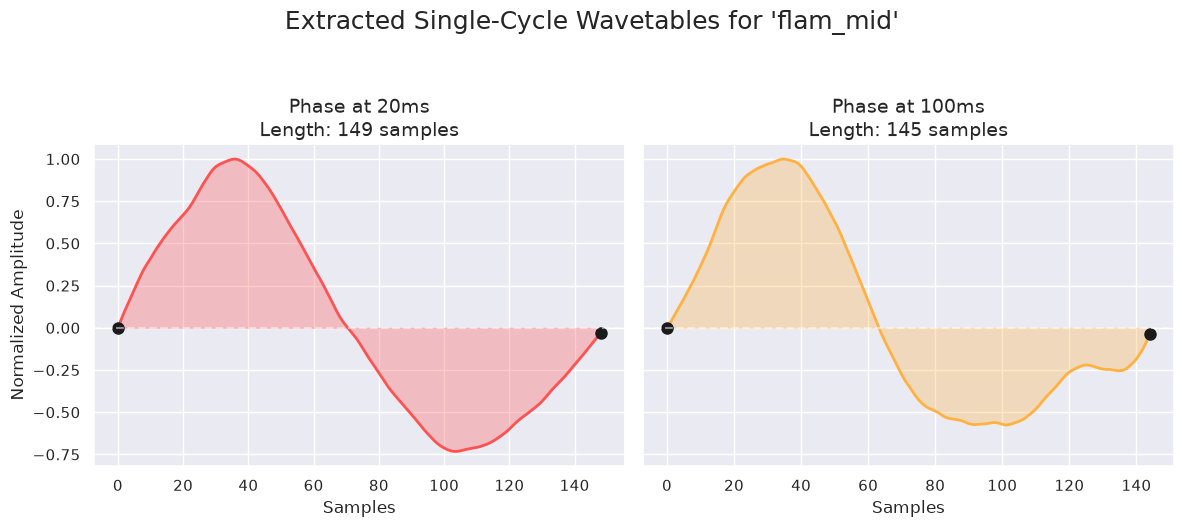

In [5]:
if len(cycles) > 0:
    fig, axes = plt.subplots(1, len(cycles), figsize=(6 * len(cycles), 5), sharey=True)
    fig.suptitle(f"Extracted Single-Cycle Wavetables for '{TARGET_STROKE}'", fontsize=18, y=1.05)

    # Handle the case where there's only 1 cycle extracted (axes is not an array)
    if len(cycles) == 1:
        axes = [axes]
        
    colors = ["#ff5252", "#ffb142", "#33d9b2", "#34ace0"]

    for i, (ax, cycle, name) in enumerate(zip(axes, cycles, cycle_names)):
        color = colors[i % len(colors)]
        ax.plot(cycle, color=color, linewidth=2)
        ax.fill_between(range(len(cycle)), cycle, color=color, alpha=0.3)
        
        ax.plot(0, cycle[0], 'ko', markersize=8)
        ax.plot(len(cycle)-1, cycle[-1], 'ko', markersize=8)
        
        ax.set_title(f"{name}\nLength: {len(cycle)} samples", fontsize=14)
        ax.set_xlabel("Samples")
        ax.axhline(0, color='white', alpha=0.5, linestyle='--')

    axes[0].set_ylabel("Normalized Amplitude")
    plt.tight_layout()
    plt.show()